# Resultados exploratorios: pendiente y estrato socioeconómico en Medellín

**Curso:** Análisis Geoespacial (UNAL, 2026-II). Este cuaderno permite **consultar y representar** los datos calculados previamente durante una exploración del territorio.

**Importante:** los archivos que leemos aquí son **resultados derivados**, no las fuentes geográficas originales. Este cuaderno **no reproduce el procesamiento del MDS, sus correcciones ni el cálculo espacial de las pendientes**. El procedimiento original no está validado como un modelo de terreno desnudo. No representa todavía un indicador de movilidad ni de accesibilidad.

Se necesitan `pandas` y `matplotlib`. El notebook y los archivos CSV deben estar en la misma carpeta. No utiliza rutas específicas de un computador.


In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Permite ejecutar desde esta carpeta o desde la raíz del repositorio.
carpeta = Path.cwd()
if not (carpeta / "resumen_pendiente_por_estrato.csv").exists():
    carpeta = carpeta / "Datos"

resumen = pd.read_csv(carpeta / "resumen_pendiente_por_estrato.csv")
distribucion = pd.read_csv(carpeta / "distribucion_pendiente_por_estrato.csv")
print("Archivos cargados desde:", carpeta.resolve())


Archivos cargados desde: /mnt/data/seleccion_datos_github


## 1. Estadísticos de pendiente por estrato

Los valores de pendiente se expresan **en grados**. La cantidad `pixeles` se refiere a las celdas consideradas durante el cálculo original.

In [2]:
display(resumen.round(2))

,estrato,pixeles,pendiente_media,pendiente_mediana,p25,p75,p90,p95,maxima
0,1,78217,22.70,22.30,15.02,29.89,36.58,40.24,65.39
1,2,607472,23.66,22.91,14.44,32.09,39.84,44.08,66.40
2,3,159464,16.07,14.37,8.94,21.43,29.64,34.93,62.90
3,4,95531,18.13,16.35,9.55,25.39,33.97,38.82,68.99
4,5,41716,15.18,13.27,7.86,20.92,29.10,33.92,62.38
5,6,65100,20.62,19.43,12.03,28.17,35.95,40.41,62.38


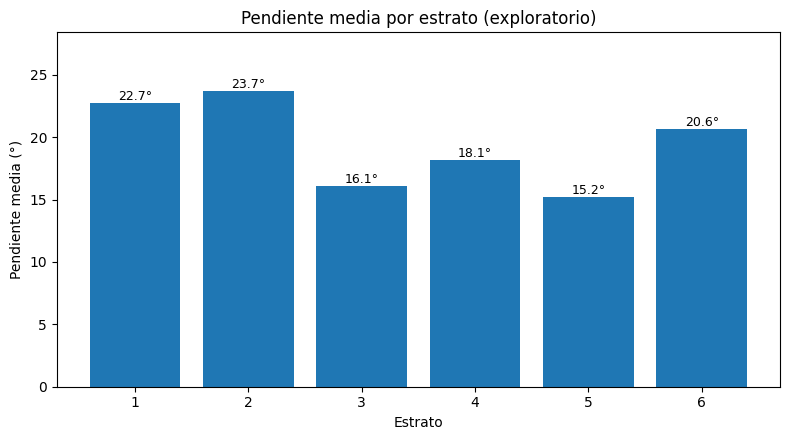

In [3]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(resumen["estrato"].astype(str), resumen["pendiente_media"])
ax.set(title="Pendiente media por estrato (exploratorio)", xlabel="Estrato", ylabel="Pendiente media (°)")
ax.set_ylim(0, max(resumen["pendiente_media"]) * 1.2)
for i, v in enumerate(resumen["pendiente_media"]):
    ax.text(i, v + 0.25, f"{v:.1f}°", ha="center", fontsize=9)
plt.tight_layout()
plt.show()


## 2. Distribución de rangos de pendiente

Porcentajes por rango de pendiente expresado en **grados**. Cada barra representa la distribución dentro de la categoría de estrato.

In [4]:
display(distribucion.round(2))

,estrato,< 10°,10–20°,20–30°,30–40°,> 40°
0,1,11.56,30.40,33.34,19.43,5.28
1,2,13.21,28.17,28.44,20.40,9.78
2,3,29.83,41.13,19.49,7.28,2.26
3,4,26.67,34.52,22.78,11.91,4.12
4,5,34.91,37.70,18.49,7.41,1.49
5,6,18.40,33.49,27.20,15.53,5.38


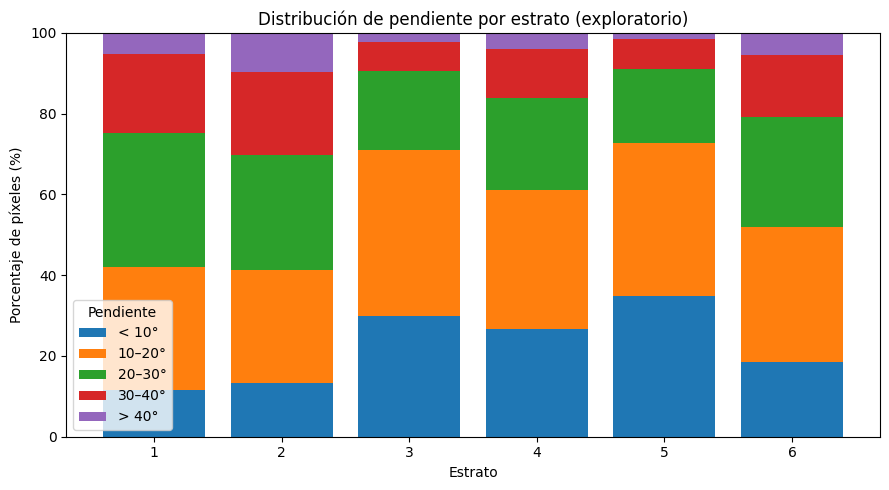

In [5]:
fig, ax = plt.subplots(figsize=(9, 5))
columnas = [c for c in distribucion.columns if c != "estrato"]
base = [0.0] * len(distribucion)
for categoria in columnas:
    valores = distribucion[categoria].to_numpy()
    ax.bar(distribucion["estrato"].astype(str), valores, bottom=base, label=categoria)
    base = [b + v for b, v in zip(base, valores)]
ax.set(title="Distribución de pendiente por estrato (exploratorio)", xlabel="Estrato", ylabel="Porcentaje de píxeles (%)", ylim=(0, 100))
ax.legend(title="Pendiente")
plt.tight_layout()
plt.show()


## 3. Mapa de estratificación empleado como referencia

![Mapa exploratorio de estratificación socioeconómica](estrato_socioeconomico_medellin.png)

## 4. Límites del ejercicio y próximos pasos

- El origen de los polígonos, la fecha de corte de la estratificación y el modelo de elevación deben verificarse con metadatos oficiales.
- Los valores de pendiente proceden de **correcciones experimentales de un modelo de superficie**, por lo que deben considerarse **provisionales**.
- Estas tablas sirven para caracterización territorial. Todavía **no** miden accesibilidad, tiempos de viaje, conectividad vial ni oportunidades urbanas.
- El siguiente paso del curso será construir esos indicadores y relacionarlos con las condiciones del territorio.
